In [2]:
import numpy as np
import re
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import remove_stopwords
from sklearn.decomposition import PCA

In [6]:
tw = open("document3.txt",encoding="UTF-8").read()
sents = [simple_preprocess(remove_stopwords(t.lower())) for t in re.split(r"[.!?]",tw)]
sents = [s for s in sents if s]

In [7]:
wv = Word2Vec(sents,vector_size=50,window=3,min_count=1,sg=0,epochs=100,workers=1).wv

In [9]:
print("vocabulary:",len(wv))

vocabulary: 61


In [10]:
print(wv.most_similar("virus",topn=5))

[('symptoms', 0.5290665030479431), ('covid', 0.520415186882019), ('prior', 0.49200090765953064), ('appearance', 0.4774704575538635), ('hours', 0.4699375629425049)]


In [11]:
print(wv.similarity("virus","influenza"))

0.29141262


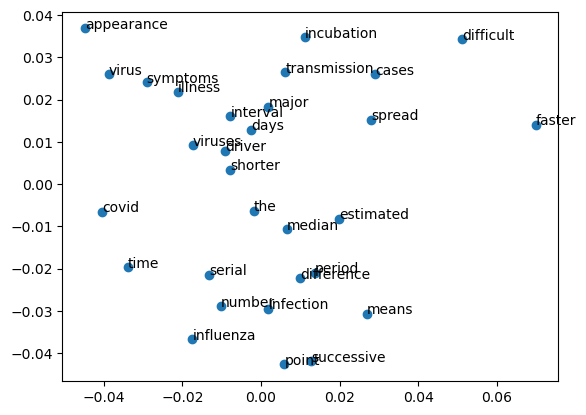

In [12]:
words = wv.index_to_key[:30]
xy = PCA(2).fit_transform(wv[words])                   # 2-D map of the words
plt.scatter(*xy.T)
[plt.annotate(a, p) for a, p in zip(words, xy)]
plt.show()      # close points = related words